Original X shape: (70000, 28, 28)
Original y shape: (70000,)
After reshape: (70000, 784)
Training set: (49000, 784)
Test set: (21000, 784)
K = 1, Accuracy = 0.9701
K = 3, Accuracy = 0.9720
K = 5, Accuracy = 0.9691
K = 7, Accuracy = 0.9682
K = 9, Accuracy = 0.9661
K = 11, Accuracy = 0.9651
K = 13, Accuracy = 0.9648
K = 15, Accuracy = 0.9637
K = 17, Accuracy = 0.9620
K = 19, Accuracy = 0.9611


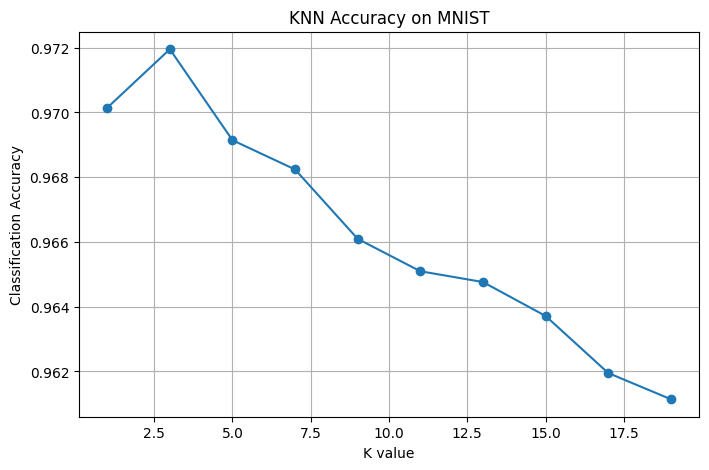

Best K: 3
Best accuracy: 0.9719523809523809


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

(X_train_original, y_train_original), (X_test_original, y_test_original) = mnist.load_data()
X = np.concatenate((X_train_original, X_test_original), axis=0)
y = np.concatenate((y_train_original, y_test_original), axis=0)

print("Original X shape:", X.shape)
print("Original y shape:", y.shape)

# Each image is 28x28, so we reshape it into a vector of length 784
X = X.reshape(X.shape[0], -1)
X = X.astype(np.float32) / 255.0
print("After reshape:", X.shape)
np.random.seed(42)
indices = np.arange(len(X))
np.random.shuffle(indices)
X = X[indices]
y = y[indices]
split_index = int(0.7 * len(X))
X_train = X[:split_index]
y_train = y[:split_index]
X_test = X[split_index:]
y_test = y[split_index:]
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
k_values = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19]
max_k = max(k_values)

def knn_predict_multiple_k(X_train, y_train, X_test, k_values, batch_size=100):
    max_k = max(k_values)
    predictions = {}
    for k in k_values:
        predictions[k] = []

    for start in range(0, len(X_test), batch_size):
        end = min(start + batch_size, len(X_test))
        X_batch = X_test[start:end]

        # Euclidean distance:
        # ||a-b||^2 = ||a||^2 + ||b||^2 - 2ab
        train_squared = np.sum(X_train ** 2, axis=1)
        test_squared = np.sum(X_batch ** 2, axis=1).reshape(-1, 1)

        distances = test_squared + train_squared - 2 * np.dot(X_batch, X_train.T)

        # Get indices of max_k nearest neighbors
        nearest_indices = np.argpartition(distances, max_k, axis=1)[:, :max_k]

        # Sort the selected neighbors by actual distance
        row_indices = np.arange(distances.shape[0])[:, None]
        sorted_order = np.argsort(distances[row_indices, nearest_indices], axis=1)
        nearest_indices = nearest_indices[row_indices, sorted_order]

        nearest_labels = y_train[nearest_indices]

        # Majority vote for each K
        for row in nearest_labels:
            for k in k_values:
                labels_k = row[:k]
                predicted_label = np.bincount(labels_k, minlength=10).argmax()
                predictions[k].append(predicted_label)

    for k in k_values:
        predictions[k] = np.array(predictions[k])

    return predictions

predictions = knn_predict_multiple_k(X_train, y_train, X_test, k_values, batch_size=100)

accuracies = []
for k in k_values:
    accuracy = np.mean(predictions[k] == y_test)
    accuracies.append(accuracy)
    print(f"K = {k}, Accuracy = {accuracy:.4f}")
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o')
plt.xlabel("K value")
plt.ylabel("Classification Accuracy")
plt.title("KNN Accuracy on MNIST")
plt.grid(True)
plt.show()
best_index = np.argmax(accuracies)
best_k = k_values[best_index]
best_accuracy = accuracies[best_index]

print("Best K:", best_k)
print("Best accuracy:", best_accuracy)